# Substitution Cipher — Evaluation and Analysis

Produces every substitution-cipher number in the paper, from one place and one preprocessing path.

**What changed relative to the previous harness**

1. Models and classical solvers now run on the **same space-free text**, the **same anchored slices** and the **same keys**, so they solve identical problem instances. Previously the classical path kept spaces (which left word boundaries unencrypted) and drew different slices with different keys.
2. The n-gram tables are paired correctly (trigrams scored against the trigram table, bigrams against the bigram table). In the previous version they were swapped, so the hand-entered Turkish tables contributed nothing.
3. Simulated annealing is vectorized (~20x) and its score is normalized per character, so one temperature schedule means the same thing at every length and the solver can be run at **all** lengths with an undiminished budget.
4. Timing is measured but **not reported in the paper table** — the model runs batched on a GPU and the classical solvers single-threaded on CPU, so the comparison would not be meaningful.

**Order of execution:** run the cells top to bottom. Set `NUM_SAMPLES` low for a smoke test.

## 0 · Setup

In [20]:
import sys
from pathlib import Path

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_DIR = Path('/content/drive/MyDrive/cryptanalysis-ai')
    %pip install -q pytorch-lightning torchmetrics matplotlib
else:
    REPO_DIR = Path.cwd()
    if REPO_DIR.name == 'notebooks':
        REPO_DIR = REPO_DIR.parent

SRC = REPO_DIR / 'src'
assert SRC.exists(), f'src not found: {SRC}'
sys.path.insert(0, str(SRC))
print('Repo:', REPO_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repo: /content/drive/MyDrive/cryptanalysis-ai


In [21]:
import json, math, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import config
from models.substitution_bte.lightning import SubstitutionCipherSolverBase   # BTE
from models.substitution_fate.lightning import SubstitutionCipherSolverFreq   # FATE
from models.substitution_common import evaluation as ev
from models.substitution_common import classical as cl
from models.substitution_common import sa_fast as SF      # <- place sa_fast.py here

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ALPHABET = config.ALPHABET
assert " " not in ALPHABET, "ALPHABET must be space-free"
assert cl.ALPHABET == ALPHABET, (
    f"classical.ALPHABET ({len(cl.ALPHABET)}) != config.ALPHABET ({len(ALPHABET)}); "
    "update classical.py (remove the space from ALPHABET and TR_ORDER)"
)

print(config.describe(), "\nDEVICE:", DEVICE, "| alphabet:", len(ALPHABET))

IN_COLAB     = True
PROJECT_ROOT = /content/drive/MyDrive/cryptanalysis-ai
STORAGE_ROOT = /content/drive/MyDrive/cryptanalysis-ai
DATA_DIR     = /content/drive/MyDrive/cryptanalysis-ai/data
CHECKPOINT   = /content/drive/MyDrive/cryptanalysis-ai/checkpoints
TB_LOG_DIR   = /content/drive/MyDrive/cryptanalysis-ai/tb_logs 
DEVICE: cpu | alphabet: 29


In [22]:
CKPT_BTE  = config.find_checkpoint("substitution_bte",  prefer="best")
CKPT_FATE = config.find_checkpoint("substitution_fate", prefer="best")

assert CKPT_BTE and CKPT_FATE, "checkpoint not found"
print("BTE :", CKPT_BTE.name, "\nFATE:", CKPT_FATE.name)

model_bte  = SubstitutionCipherSolverBase.load_from_checkpoint(str(CKPT_BTE),  map_location=DEVICE)
model_fate = SubstitutionCipherSolverFreq.load_from_checkpoint(str(CKPT_FATE), map_location=DEVICE)

for m in (model_bte, model_fate):
    m.eval(); m.freeze()

MODELS = {"BTE": model_bte, "FATE": model_fate}
print("models loaded")

BTE : best-epoch=248-val_acc=0.9570.ckpt 
FATE: best-epoch=248-val_acc=0.9574.ckpt
models loaded


In [23]:
with open(config.data_file("validation_set.txt"), encoding="utf-8") as f:
    raw_validation = f.read().replace("\n", " ")

from models.substitution_common import inference as infer
TEXT = infer.clean_text(raw_validation, ALPHABET)          # space-free, lowercased

TEST_LENGTHS = [30, 50, 75, 100, 200, 256, 300, 400, 500, 1000]
NUM_SAMPLES  = 200
ANCHOR       = max(TEST_LENGTHS)

print(f"raw: {len(raw_validation):,} chars -> cleaned: {len(TEXT):,} chars")
print(f"lengths: {TEST_LENGTHS}  |  samples per cell: {NUM_SAMPLES}")

raw: 4,796,873 chars -> cleaned: 4,137,207 chars
lengths: [30, 50, 75, 100, 200, 256, 300, 400, 500, 1000]  |  samples per cell: 200


## 1 · Neural models`run_model_comparison` returns per-sample accuracies as well as means, so thebootstrap below needs no second inference pass. `key_acc` is the share of thecipher symbols actually present in a sample that were mapped to the rightplaintext symbol under CONSISTENT decoding; `key_cov` is how much of thealphabet appears at all, which bounds what any attack could recover.

In [24]:
t0 = time.perf_counter()
results = ev.run_model_comparison(
    MODELS, raw_validation, TEST_LENGTHS, alphabet_chars=ALPHABET,
    num_samples=NUM_SAMPLES, seq_len=512, stride=400, device=DEVICE
)
print(f"done in {time.perf_counter()-t0:.0f} s")
ev.print_comparison_table(results)

done in 1275 s
LEN    | BTE RAW% BTE CONS% BTE ms  BTE KEY% | FATE RAW% FATE CONS% FATE ms FATE KEY%
-------------------------------------------------------------------------------------
30     | 35.02    33.10     73.79   25.33    | 33.77    31.93     74.16   24.98   
50     | 56.74    54.17     74.59   43.36    | 58.38    55.71     76.34   44.25   
75     | 74.73    72.54     75.94   61.37    | 75.26    73.28     77.81   62.02   
100    | 86.33    84.89     78.41   75.67    | 86.17    84.90     80.93   75.28   
200    | 98.27    98.13     89.47   93.85    | 98.41    98.38     92.63   94.09   
256    | 99.26    99.22     93.33   96.33    | 99.26    99.23     97.36   96.08   
300    | 97.18    99.26     173.79  96.00    | 97.19    99.14     179.49  95.45   
400    | 98.84    99.40     180.52  97.00    | 98.88    99.34     187.99  96.70   
500    | 97.89    99.73     266.76  98.01    | 97.86    99.70     273.79  97.85   
1000   | 99.10    99.91     460.27  98.94    | 99.09    99.91     

In [25]:
print(f"{'LEN':<6} | {'COV%':<6} | {'BTE key%':<9} {'BTE exact%':<11} | {'FATE key%':<10} {'FATE exact%'}")
print("-" * 68)
for L in TEST_LENGTHS:
    b, f = results["BTE"][L], results["FATE"][L]
    print(f"{L:<6} | {b['key_cov']:<6.1f} | {b['key_acc']:<9.2f} {b['exact_key']:<11.2f} | "
          f"{f['key_acc']:<10.2f} {f['exact_key']:.2f}")

LEN    | COV%   | BTE key%  BTE exact%  | FATE key%  FATE exact%
--------------------------------------------------------------------
30     | 53.2   | 25.33     0.00        | 24.98      0.00
50     | 66.1   | 43.36     0.00        | 44.25      0.50
75     | 75.0   | 61.37     1.50        | 62.02      1.50
100    | 80.6   | 75.67     4.50        | 75.28      7.00
200    | 90.2   | 93.85     30.00       | 94.09      31.00
256    | 92.5   | 96.33     42.50       | 96.08      44.50
300    | 93.9   | 96.00     39.50       | 95.45      40.50
400    | 95.5   | 97.00     52.50       | 96.70      54.50
500    | 96.3   | 98.01     63.00       | 97.85      61.00
1000   | 97.6   | 98.94     77.00       | 99.03      79.50


### 1.1 · Is the frequency token worth anything?Paired bootstrap over the 500 matched samples (same key, same plaintext for bothmodels), resampled at the **text** level — characters inside one sample share akey and are not independent, so resampling characters would inflate `n` and makea negligible difference look significant.

In [26]:
print("RAW decoding")
ev.print_paired_table(results, a="FATE", b="BTE", mode="raw")
print("\nCONSISTENT decoding")
ev.print_paired_table(results, a="FATE", b="BTE", mode="cons")

RAW decoding
LEN    | FATE %   BTE %    DIFF     95% CI
--------------------------------------------------------
30     | 33.77    35.02    -1.25    [-3.07, +0.57]
50     | 58.38    56.74    +1.64    [-0.30, +3.62]
75     | 75.26    74.73    +0.53    [-0.93, +1.97]
100    | 86.17    86.33    -0.16    [-1.26, +0.95]
200    | 98.41    98.27    +0.15    [-0.10, +0.41]
256    | 99.26    99.26    +0.00    [-0.12, +0.12]
300    | 97.19    97.18    +0.00    [-0.22, +0.22]
400    | 98.88    98.84    +0.03    [-0.12, +0.19]
500    | 97.86    97.89    -0.03    [-0.17, +0.11]
1000   | 99.09    99.10    -0.00    [-0.07, +0.06]

CONSISTENT decoding
LEN    | FATE %   BTE %    DIFF     95% CI
--------------------------------------------------------
30     | 31.93    33.10    -1.17    [-3.12, +0.78]
50     | 55.71    54.17    +1.54    [-0.60, +3.75]
75     | 73.28    72.54    +0.74    [-1.01, +2.51]
100    | 84.90    84.89    +0.01    [-1.40, +1.44]
200    | 98.38    98.13    +0.25    [-0.07, +0.58]
2

**Reading this table.** Two things matter and they are different questions:- *Magnitude.* How large is the gap, in points? This is the quantity the paper  reports. A gap of 0.05 points carries no practical weight even if the interval  excludes zero.- *Sign stability.* At which lengths does the interval contain zero, and does the  sign flip anywhere? A gap that changes sign across lengths is noise, whatever  its individual intervals say.Note also that the explicit histogram is a **deterministic function of theciphertext**: it adds no information the encoder cannot compute. The question itanswers is therefore about inductive bias and sample efficiency, not aboutinformation — which is why the learning-curve comparison in §5 matters more thanthe final-accuracy comparison here.

## 2 · Classical baselinesThe solver's language model is estimated from `LM_TEXT`. It defaults to thevalidation text, which gives the baseline a language model fitted to the verytext it decrypts — a deliberate advantage, stated in the paper. Pass a held-outcorpus to remove it.`w_static` blends the hand-entered Turkish tables with corpus-estimated ones.The hand-entered tables were compiled from spaced Turkish, so in space-free textevery n-gram crossing a word boundary is missing from them; `w_static=0.0` usesonly corpus tables, which match the preprocessing exactly. Both are swept below.

In [27]:
LM_TEXT = raw_validation        # or a held-out corpus
LMS = {}
for w in (0.0, 0.6):
    tg_lp, floor_t, bg_lp, floor_b = ev.build_language_model(LM_TEXT, ALPHABET, w_static=w)
    LMS[w] = SF.prepare_lm(tg_lp, floor_t, bg_lp, floor_b)
    print(f"w_static={w}: {len(tg_lp):,} trigrams, {len(bg_lp):,} bigrams")

# the temperature schedule has to match the scale of a single swap
probe_key = ev.get_fixed_key(0, ALPHABET)
probe = ev._slice(TEXT, 0, 256, ANCHOR).translate(str.maketrans(probe_key))
for w, lm in LMS.items():
    d = SF.typical_delta(probe, lm)
    print(f"w_static={w}: median |delta| per swap = {d:.4f}  "
          f"-> a sensible T_start is around {d:.2f}-{3*d:.2f}")

w_static=0.0: 14,970 trigrams, 816 bigrams
w_static=0.6: 14,970 trigrams, 816 bigrams
w_static=0.0: median |delta| per swap = 0.1629  -> a sensible T_start is around 0.16-0.49
w_static=0.6: median |delta| per swap = 0.0756  -> a sensible T_start is around 0.08-0.23


In [28]:
def run_sa_eval(lm, lengths, num_samples=500, max_iter=15000, restarts=2,
                T_start=0.2, T_end=0.005, text=None, anchor=None, verbose=False):
    """Simulated annealing over the same slices and keys the models saw."""
    text = TEXT if text is None else text
    anchor = anchor or max(lengths)
    out = {}
    for L in lengths:
        accs, k_ok, k_obs, exact, ms = [], 0, 0, 0, []
        for i in range(num_samples):
            key_map = ev.get_fixed_key(i, ALPHABET)
            plain = ev._slice(text, i, L, anchor)
            cipher = plain.translate(str.maketrans(key_map))
            t0 = time.perf_counter()
            decoded, _ = SF.simulated_annealing_solve(
                cipher, lm, max_iter=max_iter, restarts=restarts,
                T_start=T_start, T_end=T_end, rng_seed=i)
            ms.append((time.perf_counter() - t0) * 1000)
            m = min(len(plain), len(decoded))
            accs.append(sum(a == b for a, b in zip(plain[:m], decoded[:m])) / m)
            n_ok, n_obs = ev._key_metrics(cipher, decoded[:m], key_map)
            k_ok += n_ok; k_obs += n_obs; exact += int(n_ok == n_obs and n_obs > 0)
        out[L] = {"acc": float(np.mean(accs)) * 100, "per_sample": accs,
                  "key_acc": k_ok / max(k_obs, 1) * 100,
                  "exact_key": exact / max(len(accs), 1) * 100,
                  "avg_ms": float(np.mean(ms))}
        if verbose:
            print(f"  L={L:<5} acc={out[L]['acc']:6.2f}%  key={out[L]['key_acc']:6.2f}%  "
                  f"{out[L]['avg_ms']:7.1f} ms")
    return out

### 2.1 · Tuning the baselineA short grid on a subset, so the configuration reported in the paper is the bestone found rather than the first one tried. This is the evidence that thebaseline was not left under-tuned.

In [29]:
TUNE_LENGTHS = [30, 100, 256]
TUNE_SAMPLES = 200
grid = []
for w in (0.0, 0.6):
    for T0 in (0.1, 0.2, 0.4):
        r = run_sa_eval(LMS[w], TUNE_LENGTHS, num_samples=TUNE_SAMPLES,
                        max_iter=15000, restarts=2, T_start=T0)
        mean_acc = float(np.mean([r[L]["acc"] for L in TUNE_LENGTHS]))
        grid.append({"w_static": w, "T_start": T0, "mean_acc": mean_acc,
                     "by_len": {L: round(r[L]["acc"], 2) for L in TUNE_LENGTHS}})
        print(f"w_static={w}  T_start={T0:<4} -> mean {mean_acc:6.2f}%   {grid[-1]['by_len']}")

best = max(grid, key=lambda g: g["mean_acc"])
W_STATIC, T_START = best["w_static"], best["T_start"]
print(f"\nselected: w_static={W_STATIC}, T_start={T_START}  (mean {best['mean_acc']:.2f}%)")

w_static=0.0  T_start=0.1  -> mean  62.66%   {30: 24.4, 100: 65.83, 256: 97.76}
w_static=0.0  T_start=0.2  -> mean  63.13%   {30: 23.53, 100: 68.5, 256: 97.35}
w_static=0.0  T_start=0.4  -> mean  62.17%   {30: 22.58, 100: 66.7, 256: 97.21}
w_static=0.6  T_start=0.1  -> mean  43.20%   {30: 19.7, 100: 39.94, 256: 69.96}
w_static=0.6  T_start=0.2  -> mean  44.10%   {30: 21.88, 100: 41.85, 256: 68.56}
w_static=0.6  T_start=0.4  -> mean  42.18%   {30: 20.83, 100: 39.84, 256: 65.86}

selected: w_static=0.0, T_start=0.2  (mean 63.13%)


### 2.2 · Budget sweepDoes the solver still improve if it is given more search? If accuracy saturates,the comparison in the paper is budget-independent and "the baseline was given toofew iterations" is answered with data rather than assertion.

In [30]:
SWEEP_LENGTHS = [30, 100, 256]
SWEEP_SAMPLES = 50
sweep = []
for max_iter, restarts in [(15_000, 2)]:
    r = run_sa_eval(LMS[W_STATIC], SWEEP_LENGTHS, num_samples=SWEEP_SAMPLES,
                    max_iter=max_iter, restarts=restarts, T_start=T_START)
    row = {"max_iter": max_iter, "restarts": restarts,
           **{L: round(r[L]["acc"], 2) for L in SWEEP_LENGTHS},
           "ms": round(float(np.mean([r[L]["avg_ms"] for L in SWEEP_LENGTHS])), 1)}
    sweep.append(row)
    print(row)

print("\nIf the last rows differ from the first by a fraction of a point, the "
      "15k x 2 configuration is at saturation and a larger budget buys nothing.")

{'max_iter': 15000, 'restarts': 2, 30: 20.93, 100: 72.86, 256: 97.58, 'ms': 1053.3}

If the last rows differ from the first by a fraction of a point, the 15k x 2 configuration is at saturation and a larger budget buys nothing.


### 2.3 · Full classical run, every length

In [31]:
print("Simulated annealing")
sa = run_sa_eval(LMS[W_STATIC], TEST_LENGTHS, num_samples=NUM_SAMPLES,
                 max_iter=15000, restarts=2, T_start=T_START, verbose=True)
print("\nHill climbing")
hc = ev.run_classical_eval("hill_climbing", raw_validation, TEST_LENGTHS,
                           alphabet_chars=ALPHABET, num_samples=NUM_SAMPLES,
                           lm_text=LM_TEXT, max_iterations=8000, restarts=3)
for L in TEST_LENGTHS:
    print(f"  L={L:<5} acc={hc[L]['acc']:6.2f}%  key={hc[L]['key_acc']:6.2f}%")

Simulated annealing
  L=30    acc= 24.73%  key= 18.75%   1005.7 ms
  L=50    acc= 39.64%  key= 29.82%   1013.4 ms
  L=75    acc= 55.23%  key= 44.72%   1011.8 ms
  L=100   acc= 70.43%  key= 59.90%   1028.5 ms
  L=200   acc= 95.34%  key= 89.28%   1090.7 ms
  L=256   acc= 98.22%  key= 94.24%   1105.9 ms
  L=300   acc= 99.14%  key= 96.31%   1120.5 ms
  L=400   acc= 99.69%  key= 98.14%   1144.7 ms
  L=500   acc= 99.85%  key= 98.87%   1184.1 ms
  L=1000  acc= 99.97%  key= 99.52%   1343.6 ms

Hill climbing
  L=30    acc= 15.95%  key= 11.42%
  L=50    acc= 21.00%  key= 14.69%
  L=75    acc= 27.79%  key= 19.65%
  L=100   acc= 32.26%  key= 24.82%
  L=200   acc= 52.45%  key= 42.97%
  L=256   acc= 62.45%  key= 52.92%
  L=300   acc= 71.69%  key= 60.84%
  L=400   acc= 77.20%  key= 69.10%
  L=500   acc= 84.91%  key= 78.22%
  L=1000  acc= 94.62%  key= 92.01%


## 3 · Distributions, not just meansAnnealing with restarts tends to be bimodal — a sample is either solved or itcollapses — while a feed-forward decoder concentrates. Two methods can share amean and behave completely differently, so the failure rate and the spread arereported alongside it.

In [32]:
def dist_stats(per_sample):
    a = np.asarray(per_sample) * 100
    return {"mean": a.mean(), "median": float(np.median(a)),
            "p25": float(np.percentile(a, 25)), "p75": float(np.percentile(a, 75)),
            "fail<50": float((a < 50).mean() * 100),
            "solved>95": float((a > 95).mean() * 100)}

print(f"{'LEN':<6} {'method':<10} | {'mean':>6} {'med':>6} {'p25':>6} {'p75':>6} "
      f"{'fail<50%':>9} {'solved>95%':>11}")
print("-" * 72)
for L in TEST_LENGTHS:
    rows = [("SA", sa[L]["per_sample"]),
            ("BTE cons",  results["BTE"][L]["cons_per_sample"]),
            ("FATE cons", results["FATE"][L]["cons_per_sample"])]
    for name, ps in rows:
        s = dist_stats(ps)
        print(f"{L:<6} {name:<10} | {s['mean']:6.2f} {s['median']:6.2f} {s['p25']:6.2f} "
              f"{s['p75']:6.2f} {s['fail<50']:9.1f} {s['solved>95']:11.1f}")
    print()

LEN    method     |   mean    med    p25    p75  fail<50%  solved>95%
------------------------------------------------------------------------
30     SA         |  24.73  20.00   6.67  40.00      83.5         0.0
30     BTE cons   |  33.10  33.33  13.33  50.00      73.5         0.0
30     FATE cons  |  31.93  30.00  13.33  46.67      76.0         0.0

50     SA         |  39.64  36.00  22.00  58.00      65.0         1.0
50     BTE cons   |  54.17  56.00  40.00  72.00      41.5         1.0
50     FATE cons  |  55.71  58.00  38.00  72.00      37.0         1.5

75     SA         |  55.23  58.67  29.33  80.00      41.5         7.0
75     BTE cons   |  72.54  78.67  61.33  86.67      16.0        10.5
75     FATE cons  |  73.28  78.00  65.33  89.33      13.0         8.0

100    SA         |  70.43  80.00  52.75  92.00      23.5        13.5
100    BTE cons   |  84.89  90.00  82.00  96.00       5.0        28.5
100    FATE cons  |  84.90  90.00  80.00  96.00       4.5        26.5

200    SA    

## 4 · Unicity distance for TurkishHow much ciphertext does *any* attack need before the key is determined at all?$$U = \frac{H(K)}{D}, \qquad H(K) = \log_2 29!, \qquad D = \log_2 29 - H_{\text{rate}}$$The entropy rate is estimated from the corpus itself. Successive conditionalentropies $H_1 > H_2 > H_3 > \dots$ approach the true rate from above, andhigh-order estimates are biased low by data sparsity, so the values below bracketrather than pin down $U$. Accuracy at the shortest lengths should be read againstthis bound, not as a shortcoming of either method.

In [33]:
def conditional_entropy(text, n):
    """H(X_n | X_1..X_{n-1}) in bits, estimated by plug-in counts."""
    N = len(text) - n + 1
    full = Counter(text[i:i+n] for i in range(N))
    if n == 1:
        return -sum((c / N) * math.log2(c / N) for c in full.values())
    ctx = Counter(text[i:i+n-1] for i in range(len(text) - n + 2))
    return -sum((c / N) * math.log2(c / ctx[g[:-1]]) for g, c in full.items())

H_KEY = sum(math.log2(i) for i in range(1, len(ALPHABET) + 1))
H_MAX = math.log2(len(ALPHABET))
print(f"H(K) = log2({len(ALPHABET)}!) = {H_KEY:.1f} bits")
print(f"log2({len(ALPHABET)}) = {H_MAX:.3f} bits/char\n")

SAMPLE = TEXT[:2_000_000]
unicity = {}
for n in (1, 2, 3):
    H = conditional_entropy(SAMPLE, n)
    D = H_MAX - H
    unicity[n] = {"H": H, "D": D, "U": H_KEY / D}
    print(f"H{n} = {H:.3f} bits/char   redundancy D = {D:.3f}   U = {H_KEY/D:5.1f} characters")

print("\nShortest evaluated length:", TEST_LENGTHS[0], "characters")

H(K) = log2(29!) = 102.8 bits
log2(29) = 4.858 bits/char

H1 = 4.381 bits/char   redundancy D = 0.477   U = 215.4 characters
H2 = 3.683 bits/char   redundancy D = 1.175   U =  87.5 characters
H3 = 3.091 bits/char   redundancy D = 1.767   U =  58.2 characters

Shortest evaluated length: 30 characters


## 5 · Figures

saved: /content/drive/MyDrive/cryptanalysis-ai/substitution_results.png


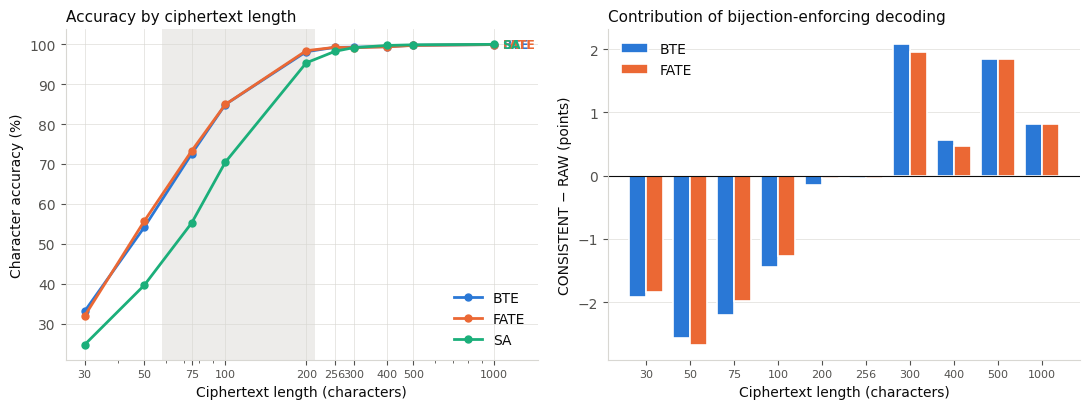

In [34]:
# validated categorical palette (CVD-safe on a light surface)
C_BTE, C_FATE, C_SA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#d8d7d2"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
L = TEST_LENGTHS
series = [
    ("BTE",  [results["BTE"][x]["cons"]  for x in L], C_BTE),
    ("FATE", [results["FATE"][x]["cons"] for x in L], C_FATE),
    ("SA",   [sa[x]["acc"]               for x in L], C_SA),
]
for name, y, c in series:
    ax.plot(L, y, "-", color=c, lw=2, marker="o", ms=5, label=name)
    ax.annotate(name, (L[-1], y[-1]), xytext=(6, 0), textcoords="offset points",
                color=c, fontsize=9, va="center", fontweight="bold")

# the unicity band: below it no attack can determine the key
u_lo, u_hi = unicity[3]["U"], unicity[1]["U"]
ax.axvspan(min(u_lo, u_hi), max(u_lo, u_hi), color=GRID, alpha=0.45, lw=0, zorder=0)
ax.annotate("unicity distance", (max(u_lo, u_hi), 20), xytext=(6, 0),
            textcoords="offset points", color=INK_MUTED, fontsize=8, va="center")

ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels(L, fontsize=8)
ax.set_xlabel("Ciphertext length (characters)")
ax.set_ylabel("Character accuracy (%)")
ax.set_title("Accuracy by ciphertext length", loc="left")
ax.set_xlim(L[0] * 0.85, L[-1] * 1.45)
ax.grid(True, color=GRID, lw=0.6, alpha=0.7)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

dB = [results["BTE"][x]["cons"]  - results["BTE"][x]["raw"]  for x in L]
dF = [results["FATE"][x]["cons"] - results["FATE"][x]["raw"] for x in L]
x = np.arange(len(L)); w = 0.38

ax2.bar(x - w/2, dB, w, color=C_BTE, label="BTE", edgecolor="white", lw=1.2)
ax2.bar(x + w/2, dF, w, color=C_FATE, label="FATE", edgecolor="white", lw=1.2)
ax2.axhline(0, color=INK, lw=0.8)
ax2.set_xticks(x); ax2.set_xticklabels(L, fontsize=8)
ax2.set_xlabel("Ciphertext length (characters)")
ax2.set_ylabel("CONSISTENT − RAW (points)")
ax2.set_title("Contribution of bijection-enforcing decoding", loc="left")
ax2.grid(True, axis="y", color=GRID, lw=0.6, alpha=0.7)
ax2.set_axisbelow(True)
ax2.legend(loc="upper left")

plt.tight_layout()
out = config.STORAGE_ROOT / "substitution_results.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
print("saved:", out)
plt.show()

## 6 · Paper tableAccuracy and key-level recovery only. Latency is omitted: the models run on aGPU and the classical solvers single-threaded on CPU, so a side-by-side timecolumn would compare hardware rather than methods.

In [35]:
hdr = (f"{'Length':<8} | {'SA':>7} {'HC':>7} | {'BTE raw':>8} {'BTE cons':>9} "
       f"| {'FATE raw':>9} {'FATE cons':>10} | {'BTE key':>8} {'FATE key':>9}")
print(hdr); print("-" * len(hdr))
for x in TEST_LENGTHS:
    b, f = results["BTE"][x], results["FATE"][x]
    print(f"{x:<8} | {sa[x]['acc']:7.2f} {hc[x]['acc']:7.2f} | {b['raw']:8.2f} {b['cons']:9.2f} "
          f"| {f['raw']:9.2f} {f['cons']:10.2f} | {b['key_acc']:8.2f} {f['key_acc']:9.2f}")

print("\nWhere does each method win?")
for x in TEST_LENGTHS:
    best = max([("SA", sa[x]['acc']), ("HC", hc[x]['acc']),
                ("BTE", results['BTE'][x]['cons']), ("FATE", results['FATE'][x]['cons'])],
               key=lambda t: t[1])
    print(f"  L={x:<5} best = {best[0]:<5} ({best[1]:.2f}%)")

Length   |      SA      HC |  BTE raw  BTE cons |  FATE raw  FATE cons |  BTE key  FATE key
-------------------------------------------------------------------------------------------
30       |   24.73   15.95 |    35.02     33.10 |     33.77      31.93 |    25.33     24.98
50       |   39.64   21.00 |    56.74     54.17 |     58.38      55.71 |    43.36     44.25
75       |   55.23   27.79 |    74.73     72.54 |     75.26      73.28 |    61.37     62.02
100      |   70.43   32.26 |    86.33     84.89 |     86.17      84.90 |    75.67     75.28
200      |   95.34   52.45 |    98.27     98.13 |     98.41      98.38 |    93.85     94.09
256      |   98.22   62.45 |    99.26     99.22 |     99.26      99.23 |    96.33     96.08
300      |   99.14   71.69 |    97.18     99.26 |     97.19      99.14 |    96.00     95.45
400      |   99.69   77.20 |    98.84     99.40 |     98.88      99.34 |    97.00     96.70
500      |   99.85   84.91 |    97.89     99.73 |     97.86      99.70 |    98.0

In [36]:
payload = {
    "config": {"lengths": TEST_LENGTHS, "num_samples": NUM_SAMPLES,
               "alphabet_size": len(ALPHABET), "device": DEVICE,
               "sa": {"w_static": W_STATIC, "T_start": T_START,
                      "max_iter": 15000, "restarts": 2},
               "hc": {"max_iterations": 8000, "restarts": 3}},
    "models": {n: {str(L): {k: v for k, v in r.items() if not k.endswith("per_sample")}
                   for L, r in results[n].items()} for n in results},
    "sa": {str(L): {k: v for k, v in r.items() if k != "per_sample"} for L, r in sa.items()},
    "hc": {str(L): {k: v for k, v in r.items() if k != "per_sample"} for L, r in hc.items()},
    "sa_tuning": grid, "sa_budget_sweep": sweep,
    "unicity": {str(k): v for k, v in unicity.items()},
}

path = config.STORAGE_ROOT / "substitution_results.json"
with open(path, "w", encoding="utf-8") as fh:
    json.dump(payload, fh, ensure_ascii=False, indent=2)
print("saved:", path)

saved: /content/drive/MyDrive/cryptanalysis-ai/substitution_results.json


## 7 · What to write upWork through these before touching the manuscript; each is a claim the currentdraft makes that these numbers either support or refute.1. **"Both transformers surpass SA at every length."** Check the win table in §6.   In the previous run this was false at L=256 for RAW decoding. State what is   actually true, length by length.2. **The frequency finding.** Report the magnitude of the FATE−BTE gap and where   its interval contains zero, not just whether it is significant. If the sign   flips across lengths, say so — it is the strongest evidence the gap is noise.3. **Whatever the classical comparison shows.** If the gap has narrowed after the   fixes, the honest framing is amortization: one forward pass, no language model   at attack time, cost that does not grow with a search budget. If SA wins   somewhere, report it.4. **Short lengths against the unicity bound.** Accuracy at 30 characters should   be read against §4, not presented as a shortcoming.5. **Distributions.** If SA's failure rate is high where its mean looks   reasonable, that is a real difference the mean hides — and it belongs in the   text even if the means are close.6. **Preprocessing, stated plainly.** Space-free, 29 symbols, length counts   alphabet characters only, identical slices and keys for all methods, classical   language model estimated from the validation corpus.